# A Stochastic Optimization Algorithm — Simulated Annealing

We minimize

$$h(x) = x^2 + 3x\cos(x), \qquad x \in [-8\pi, 8\pi],$$

and compare two algorithms started from the same point $x_0 = 7.5$, which lies in the basin of a **local**, non-global minimum:

- **gradient descent** (deterministic);
- **simulated annealing** (stochastic).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def h(x):
    return x**2 + 3 * x * np.cos(x)

x0 = 7.5

---
## 1. The function $h$

The parabola $x^2$ combined with the oscillating term $3x\cos x$ produces many local minima.

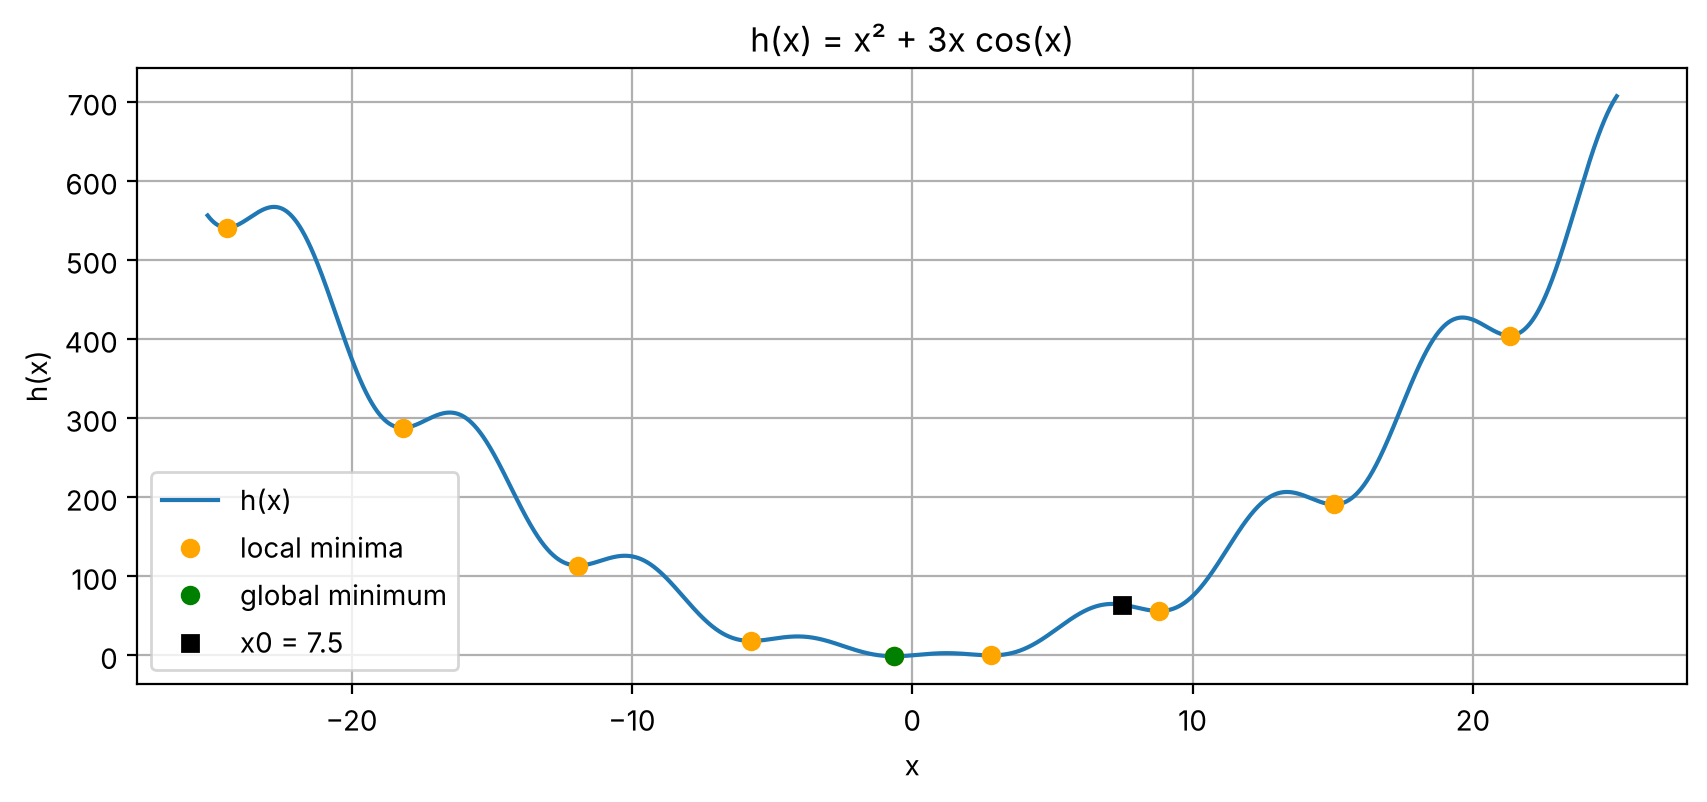

Local minima at x ≈ [-24.45 -18.17 -11.92  -5.74  -0.64   2.8    8.81  15.05  21.31]
Global minimum: x = -0.638, h = -1.130


In [2]:
y = np.linspace(-8*np.pi, 8*np.pi, 5000)
hy = h(y)
k = np.argmin(hy)

local = np.where((hy[1:-1] < hy[:-2]) & (hy[1:-1] < hy[2:]))[0] + 1

plt.figure(figsize=(10, 4))
plt.plot(y, hy, label="h(x)")
plt.plot(y[local], hy[local], "o", color="orange", label="local minima")
plt.plot(y[k], hy[k], "go", label="global minimum")
plt.plot(x0, h(x0), "ks", label="x0 = 7.5")
plt.xlabel("x"); plt.ylabel("h(x)"); plt.legend(); plt.grid(True)
plt.title("h(x) = x² + 3x cos(x)")
plt.show()

print("Local minima at x ≈", np.round(y[local], 2))
print(f"Global minimum: x = {y[k]:.3f}, h = {hy[k]:.3f}")

The global minimum is at $x \approx -0.64$. The starting point $x_0 = 7.5$ lies in the basin of the local minimum $x \approx 8.8$.

---
## 2. Gradient descent

$$x_{n+1} = x_n - \alpha_n\,h'(x_n), \qquad \alpha_n = \frac{0.025}{n}$$

Using the product rule on $3x\cos x$:

$$h'(x) = 2x + 3\cos x - 3x\sin x.$$

The step sizes satisfy $\sum \alpha_n = +\infty$ and $\sum \alpha_n^2 < +\infty$.

x0 = 7.5  ->  x_1000 = 8.6606, h = 56.2483


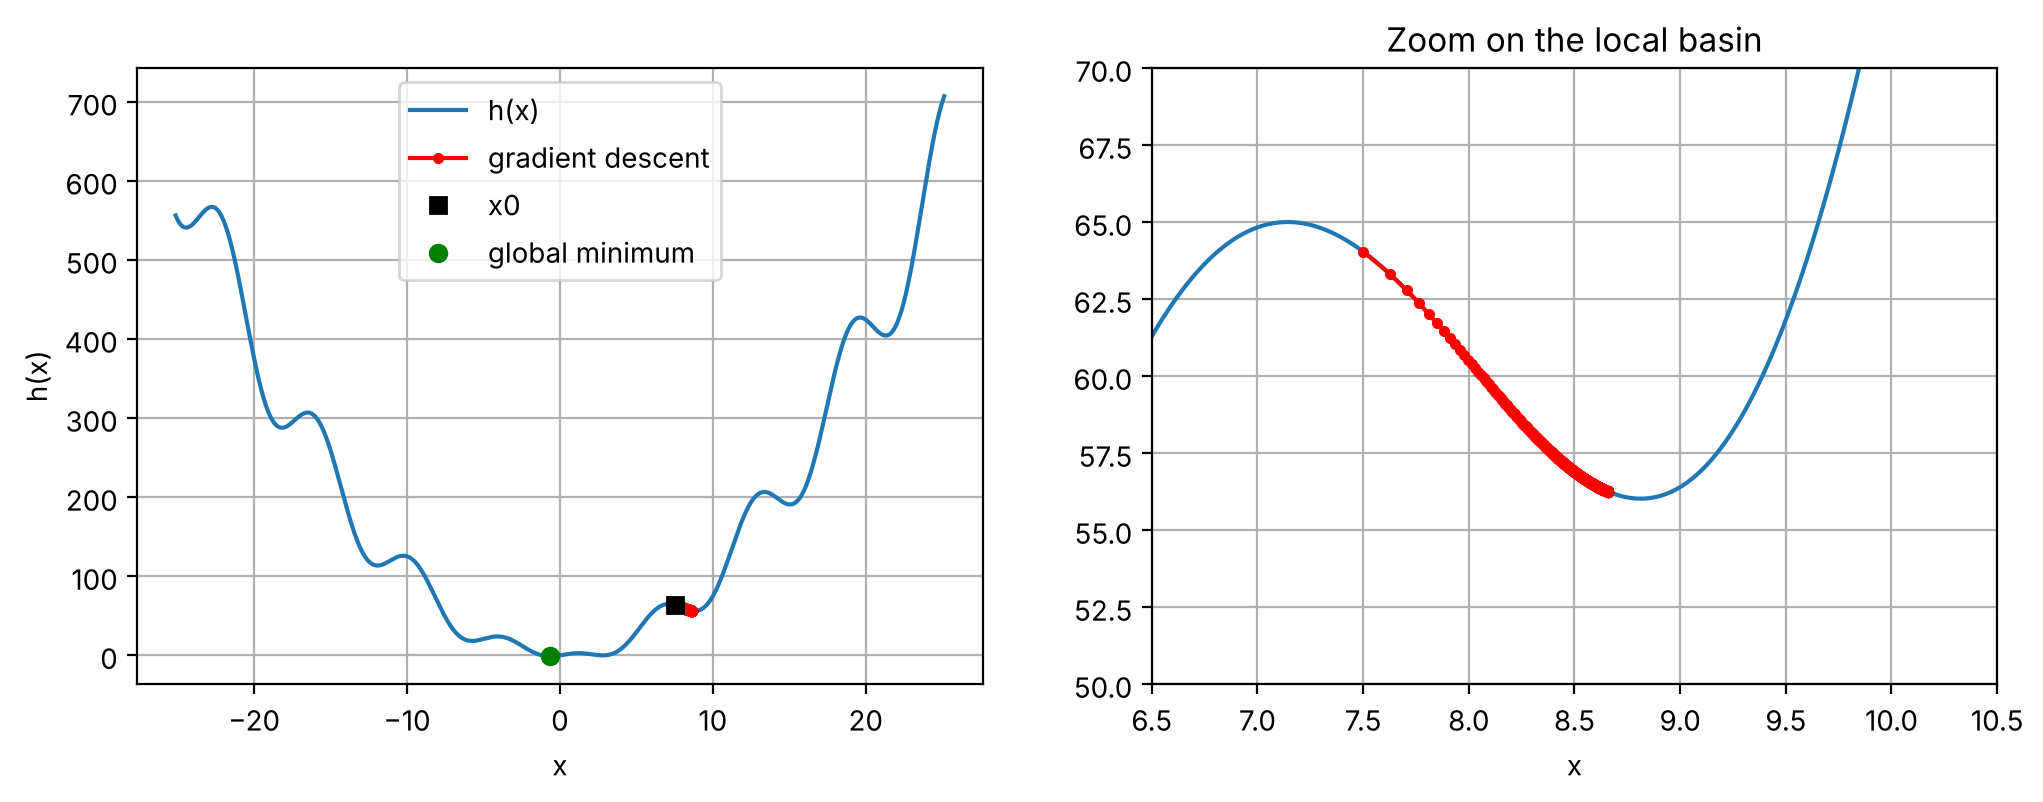

In [3]:
def dh(x):
    return 2*x + 3*np.cos(x) - 3*x*np.sin(x)

def gradient_descent(x_start, N=1000):
    x = np.zeros(N + 1)
    x[0] = x_start
    for n in range(1, N + 1):
        x[n] = x[n-1] - (0.025 / n) * dh(x[n-1])
    return x

x_grad = gradient_descent(x0)
print(f"x0 = 7.5  ->  x_1000 = {x_grad[-1]:.4f}, h = {h(x_grad[-1]):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(y, hy, label="h(x)")
ax[0].plot(x_grad, h(x_grad), "r.-", label="gradient descent")
ax[0].plot(x0, h(x0), "ks", label="x0")
ax[0].plot(y[k], hy[k], "go", label="global minimum")
ax[0].set_xlabel("x"); ax[0].set_ylabel("h(x)"); ax[0].legend(); ax[0].grid(True)

ax[1].plot(y, hy)
ax[1].plot(x_grad, h(x_grad), "r.-")
ax[1].set_xlim(6.5, 10.5); ax[1].set_ylim(50, 70)
ax[1].set_xlabel("x"); ax[1].set_title("Zoom on the local basin"); ax[1].grid(True)
plt.show()

In [4]:
for x_start in [7.5, 6, -2]:
    xf = gradient_descent(x_start)[-1]
    print(f"x0 = {x_start:>4}  ->  x_1000 = {xf:.3f}, h = {h(xf):.3f}")

x0 =  7.5  ->  x_1000 = 8.661, h = 56.248
x0 =    6  ->  x_1000 = 3.215, h = 0.717
x0 =   -2  ->  x_1000 = -0.922, h = -0.821


Gradient descent converges to the minimum of the basin it starts in: from $x_0 = 7.5$ it moves towards the local minimum $x \approx 8.8$, never towards the global minimum. It only uses the local slope and can only go downhill, so it cannot leave a basin. The limit depends on the initialization: from $x_0 = 6$ it moves towards another local minimum ($x \approx 2.8$), and only from a point inside the global basin (e.g. $x_0 = -2$) does it move towards $x \approx -0.64$. Convergence is slow at the end because $\alpha_n = 0.025/n$ becomes very small.

---
## 3. Simulated annealing

At each iteration:

1. draw $z \sim \mathcal{U}[x_n - \tfrac{\pi}{2},\ x_n + \tfrac{\pi}{2}]$, i.e. $z = x_n + \pi\,(U - 0.5)$;
2. if $h(z) \le h(x_n)$, set $x_{n+1} = z$;
3. otherwise, with $\Delta h_n = h(z) - h(x_n)$, set $x_{n+1} = z$ with probability $e^{-\Delta h_n / T_n}$, and $x_{n+1} = x_n$ otherwise.

The temperature decreases geometrically: $T_n = T_0\,\alpha^n$ with $T_0 = 500$, $\alpha = 0.99$. It does not change the step length; it controls how often uphill moves are accepted:

| | $\Delta h = 1$ | $\Delta h = 10$ | $\Delta h = 50$ |
|---|---|---|---|
| $T = 500$ | 0.998 | 0.98 | 0.90 |
| $T = 50$ | 0.98 | 0.82 | 0.37 |
| $T = 5$ | 0.82 | 0.14 | 0.00005 |
| $T = 0.5$ | 0.14 | ≈ 0 | ≈ 0 |

At high temperature the chain explores the whole domain and escapes local minima; as $T$ decreases, only improvements are accepted and the chain settles in a basin, most often the deepest one.

Final point: x = -0.5785, h = -1.1185


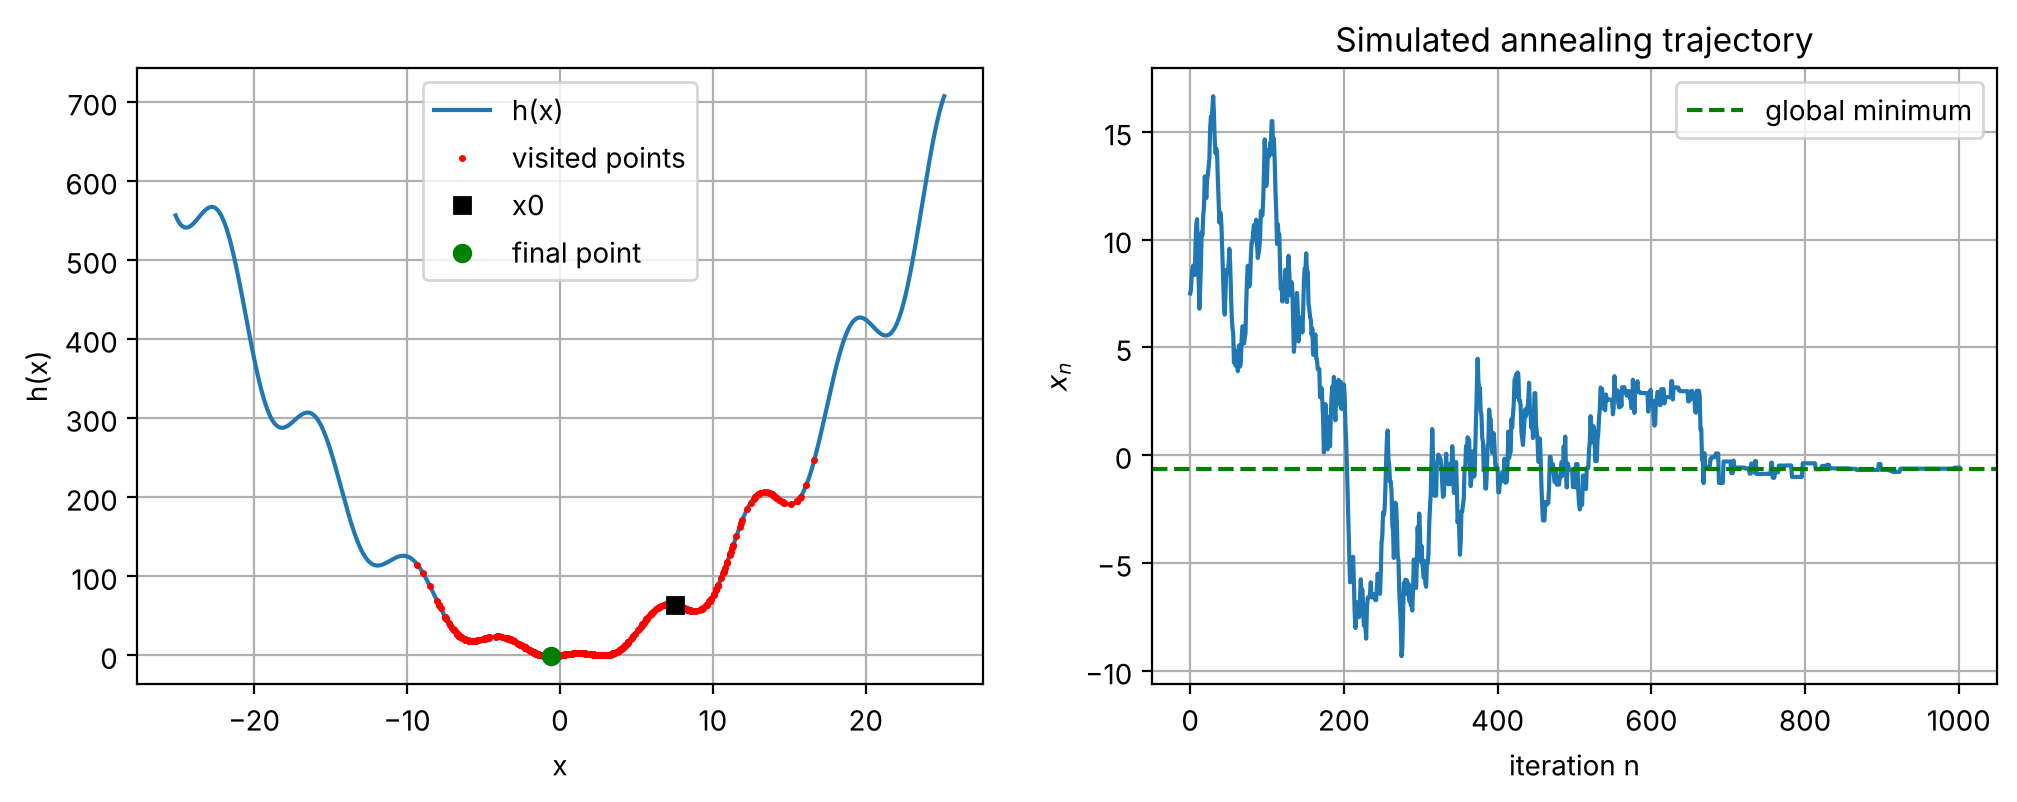

In [5]:
np.random.seed(0)

N = 1000
T0 = 500
a = 0.99

x_sa = np.zeros(N + 1)
x_sa[0] = x0

for n in range(1, N + 1):
    T = T0 * a**n
    x = x_sa[n-1]
    z = x + np.pi * (np.random.rand() - 0.5)
    if h(z) <= h(x):
        x_sa[n] = z
    elif np.random.rand() <= np.exp(-(h(z) - h(x)) / T):
        x_sa[n] = z
    else:
        x_sa[n] = x

print(f"Final point: x = {x_sa[N]:.4f}, h = {h(x_sa[N]):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(y, hy, label="h(x)")
ax[0].plot(x_sa, h(x_sa), "r.", markersize=3, label="visited points")
ax[0].plot(x0, h(x0), "ks", label="x0")
ax[0].plot(x_sa[N], h(x_sa[N]), "go", label="final point")
ax[0].set_xlabel("x"); ax[0].set_ylabel("h(x)"); ax[0].legend(); ax[0].grid(True)

ax[1].plot(x_sa)
ax[1].axhline(y[k], color="g", ls="--", label="global minimum")
ax[1].set_xlabel("iteration n"); ax[1].set_ylabel("$x_n$"); ax[1].legend(); ax[1].grid(True)
ax[1].set_title("Simulated annealing trajectory")
plt.show()

Starting from the same $x_0 = 7.5$, simulated annealing escapes the local basin, explores the domain while the temperature is high, then settles near the global minimum as it cools down.

### Success rate

The algorithm is random, so we estimate the probability of reaching the global minimum over repeated runs, for several cooling schedules.

In [6]:
def annealing_final(T0=500, a=0.99, N=1000):
    x = x0
    for n in range(1, N + 1):
        T = T0 * a**n
        z = x + np.pi * (np.random.rand() - 0.5)
        if h(z) <= h(x) or np.random.rand() <= np.exp(-(h(z) - h(x)) / T):
            x = z
    return x

runs = 100
for T0_, a_, N_ in [(500, 0.99, 1000), (50, 0.99, 1000), (500, 0.999, 10000)]:
    success = sum(abs(annealing_final(T0_, a_, N_) - y[k]) < 0.5 for _ in range(runs))
    print(f"T0 = {T0_:>3}, alpha = {a_}, N = {N_:>5}: global minimum reached in {success}/{runs} runs")

T0 = 500, alpha = 0.99, N =  1000: global minimum reached in 73/100 runs


T0 =  50, alpha = 0.99, N =  1000: global minimum reached in 72/100 runs


T0 = 500, alpha = 0.999, N = 10000: global minimum reached in 88/100 runs


The global minimum is reached in most runs; otherwise the chain ends in the neighbouring basin $x \approx 2.8$, whose value of $h$ is close to the global minimum. The success rate depends mainly on the cooling speed and hardly on $T_0$: slower cooling increases it, but convergence to the global minimum is only guaranteed asymptotically.

---
## 4. Comparison

| | Gradient descent | Simulated annealing |
|---|---|---|
| **Convergence guarantee** | Local minimum of the starting basin (global only for convex functions) | Global minimum almost surely, asymptotically; high probability in practice |
| **Dependence on $x_0$** | Strong | Weak |
| **Speed** | Fast descent, slow final convergence with $\alpha_n = 0.025/n$ | Many iterations spent exploring before settling |
| **Determinism** | Deterministic | Random: results vary between runs |
| **Information used** | Requires the derivative $h'$ | Only values of $h$ |
| **Parameters** | Step sizes $\alpha_n$ | $T_0$, $\alpha$, proposal width, number of iterations |
| **Conceptual complexity** | Simple | Requires understanding the role of temperature |

**Conclusion.** Gradient descent is simple, fast and predictable, but it only finds the local minimum of its starting basin. Simulated annealing is slower, random and has more parameters to tune, but it can escape local minima and is well suited to functions with many local minima, or to problems where no gradient is available.